# Prijsvoorspelling occasions: data voorbereiden

Doel: de prijs van een auto **over een aantal jaar** voorspellen.

De data komt uit twee bronnen, allebei alleen Nederlandse advertenties:

- `cars.csv`: de scrape van oktober 2026.
- `wayback_cars.csv`: historische advertenties van 2020–2025 via de Wayback Machine (zie `webscrape/README.md`).
  Alleen de NL-advertenties (vanaf maart 2023) zijn bruikbaar, daarvoor zijn het Duitse/Belgische auto's.

Elke rij heeft daardoor een eigen observatiejaar. In dit notebook:

1. **Samenvoegen** van de twee bronnen, met `observation_year` per rij.
2. **Inflatiecorrectie** (CBS-CPI): de nieuwprijs (euro's van het bouwjaar) en de verkoopprijs (euro's van het
   observatiejaar) worden allebei omgerekend naar euro's van 2026.
3. **Restwaarde berekenen**: `prijs / nieuwprijs`, het doel voor het model.
4. **Willekeurige train/val/test-split**.

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split

OBSERVATIE_JAAR = 2026        # jaar van de cars.csv-scrape; alle bedragen gaan naar euro's van dit jaar
SCRAPE_DATUM = "2026-10-05"   # einde van de cars.csv-scrape
RANDOM_STATE = 42

## 1. Data inladen

`cpi.csv` komt van CBS StatLine (tabel 86141NED, aangevuld met 83131NED voor 2005–2009, 2025 = 100).
Opnieuw downloaden: `python fetch_cpi.py`.

In [ ]:
df = pd.read_csv("../webscrape/data/cars.csv")
wb = pd.read_csv("../webscrape/data/wayback_cars.csv")
cpi = pd.read_csv("cpi.csv", index_col="year")

print("cars.csv:", df.shape)
print("wayback_cars.csv:", wb.shape)
cpi.tail()

### Samenvoegen met de Wayback-data

- `cars.csv` is gescraped met het zoekfilter `cy=NL`, dus alles is NL en heeft één meetmoment.
- Van de Wayback-data houden we alleen `country == "NL"` met `page_sort == "standard"`.
  Duitse prijzen zijn lager (geen BPM), en op de oude pagina's (`page_sort == "price"`) staan alleen de goedkoopste auto's.
- De nieuwprijs ontbreekt bijna altijd in de Wayback-data. Die hoort bij merk + model + bouwjaar en niet bij het
  meetmoment, dus nemen we de mediaan uit `cars.csv` (zelfde aanpak als `estimate_new_prices.py`).
- `body_type` staat niet op de NL-snapshots: die wordt `unknown`.

In [ ]:
df["snapshot_date"] = SCRAPE_DATUM
df["country"] = "NL"
df["bron"] = "scrape_2026"

wb = wb[(wb["country"] == "NL") & (wb["page_sort"] == "standard")]
wb = wb.dropna(subset=["year"]).astype({"year": int})
wb["bron"] = "wayback"
wb["body_type"] = wb["body_type"].fillna("unknown")
wb["new_price_source"] = wb["new_price_source"].astype(object)

mediaan = (
    df.groupby(["brand", "model", "year"])["new_price_eur"].median()
    .rename("new_price_mediaan")
    .reset_index()
)
wb = wb.merge(mediaan, on=["brand", "model", "year"], how="left")
ontbreekt = wb["new_price_eur"].isna() & wb["new_price_mediaan"].notna()
wb.loc[ontbreekt, "new_price_eur"] = wb.loc[ontbreekt, "new_price_mediaan"]
wb.loc[ontbreekt, "new_price_source"] = "schatting"

df = pd.concat([df, wb[df.columns]], ignore_index=True)
df["snapshot_date"] = pd.to_datetime(df["snapshot_date"])
df["observation_year"] = df["snapshot_date"].dt.year

df.groupby(["bron", "observation_year"]).size()

## 2. Opschonen

Alles met regels in plaats van indexnummers, zodat het ook na een nieuwe scrape klopt.

In [ ]:
n_start = len(df)

# Ontbrekende waarden
df = df.dropna(subset=["model", "mileage_km", "new_price_eur"])

# Onrealistische waarden
df = df[df["mileage_km"] < 1_000_000]
df = df[df["new_price_eur"] >= 5_000]
df = df[df["year"] <= df["observation_year"]]

# Prijs ver boven de nieuwprijs: placeholderprijzen (99.999.999) of verzamelobjecten
# die in waarde stijgen (bijv. Carrera GT). Die vallen buiten wat dit model wil voorspellen.
df = df[df["price_eur"] <= 1.5 * df["new_price_eur"]]

df = df.reset_index(drop=True)
print(f"{n_start} -> {len(df)} rijen ({n_start - len(df)} verwijderd)")

## 3. Features

- `age`: leeftijd van de auto op het moment van de advertentie. Dit is de feature die we straks ophogen om in de toekomst te kijken.
- `observation_year`: jaar van de advertentie, zodat het model marktontwikkeling over de tijd kan leren.
- `new_price_2026`: nieuwprijs omgerekend van het bouwjaar naar euro's van 2026 met de algemene CPI.
- `price_2026`: verkoopprijs omgerekend van het observatiejaar naar euro's van 2026.
- `restwaarde`: het doel, `price_2026 / new_price_2026`.
- `new_price_estimated`: of de nieuwprijs een schatting is (minder betrouwbaar).
- `brand_model`: merk + model samen.

In [ ]:
df["age"] = df["observation_year"] - df["year"]

cpi_doel = cpi.loc[OBSERVATIE_JAAR, "cpi_all"]
df["new_price_2026"] = (df["new_price_eur"] * cpi_doel / df["year"].map(cpi["cpi_all"])).round()
df["price_2026"] = (df["price_eur"] * cpi_doel / df["observation_year"].map(cpi["cpi_all"])).round()
df["restwaarde"] = df["price_2026"] / df["new_price_2026"]

df["new_price_estimated"] = (df["new_price_source"] == "schatting").astype(int)
df["brand_model"] = df["brand"] + " " + df["model"]

df[["brand_model", "observation_year", "year", "age", "new_price_2026", "price_2026", "restwaarde"]].head()

Controle: de afschrijvingscurve (mediane restwaarde per leeftijd).

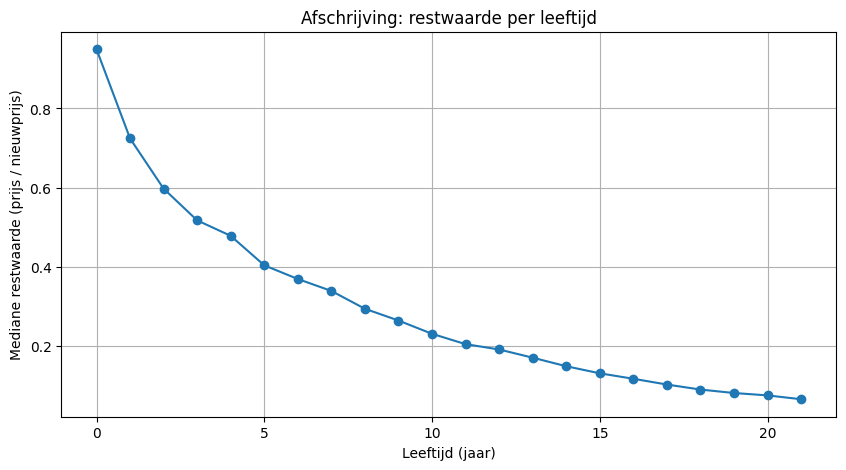

In [5]:
curve = df.groupby("age")["restwaarde"].median()

plt.figure(figsize=(10, 5))
plt.plot(curve.index, curve.values, marker="o")
plt.xlabel("Leeftijd (jaar)")
plt.ylabel("Mediane restwaarde (prijs / nieuwprijs)")
plt.title("Afschrijving: restwaarde per leeftijd")
plt.grid(True)
plt.show()

## 4. Train / validatie / test

Willekeurige split 70 / 15 / 15. De test set gebruik je pas helemaal aan het eind.

In [ ]:
CATEGORISCH = ["brand", "brand_model", "fuel_type", "transmission", "body_type"]
NUMERIEK = ["age", "observation_year", "mileage_km", "new_price_2026", "new_price_estimated"]
FEATURES = CATEGORISCH + NUMERIEK

X = df[FEATURES]
y = df["restwaarde"]

X_train, X_rest, y_train, y_rest = train_test_split(X, y, test_size=0.30, random_state=RANDOM_STATE)
X_val, X_test, y_val, y_test = train_test_split(X_rest, y_rest, test_size=0.50, random_state=RANDOM_STATE)

print("Train:", X_train.shape)
print("Validatie:", X_val.shape)
print("Test:", X_test.shape)

## 5. Split opslaan

Als parquet, zodat het model-notebook de split kan inladen zonder dit notebook opnieuw te draaien.
`y` is de restwaarde; de prijs in euro's is `y * X["new_price_2026"]`.

In [7]:
X_train.to_parquet("X_train.parquet", index=False)
X_val.to_parquet("X_val.parquet", index=False)
X_test.to_parquet("X_test.parquet", index=False)

y_train.to_frame().to_parquet("y_train.parquet", index=False)
y_val.to_frame().to_parquet("y_val.parquet", index=False)
y_test.to_frame().to_parquet("y_test.parquet", index=False)

## Volgende stap: model

De data is nu klaar voor het model. Het plan:

1. **Model leert de restwaarde** (`restwaarde`) uit leeftijd, kilometerstand, merk, model, ...
2. **Voorspellen over n jaar**: de auto `n` jaar ouder maken en kilometers erbij tellen → prijs in euro's van 2026.
3. **Toekomstige inflatie** daarna als scenario toepassen: `× (1 + inflatie) ** n`
   (bijv. 0%, ECB-doel 2%, CPB-raming).